# Estimates

In [1]:
import pandas as pd, numpy as np
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

clean = pd.read_csv("clean_log.csv", index_col=0)
events = pd.read_csv("events.csv")
assays = pd.read_csv("endpoint_assays.csv").set_index("bottle")
K_step = pd.read_csv("temperature_coefficients.csv", index_col=0)

BOTTLES = ["B1", "B2", "B3", "B4", "B5"]
start = pd.Timestamp("2025-03-03T16:00:00Z")
pitch_ts = pd.Timestamp(events.loc[events["event"].str.startswith("pitch"), "ts_utc"].iloc[0])
PITCH_SEQ = int((pitch_ts - start).total_seconds() / 60)
t = ((clean.index - PITCH_SEQ) / 60).values
T = clean["T_amb_C"].values
T0 = T.mean()
rng = np.random.default_rng(0)

pitch = {}
for b in BOTTLES:
    y = clean[b + "_g_clean"]
    pitch[b] = y.loc[PITCH_SEQ:PITCH_SEQ + 9].mean() - y.loc[PITCH_SEQ - 10:PITCH_SEQ - 1].mean()
pitch = pd.Series(pitch).round(3)

def gompertz(t, A, mu, lam):
    tt = np.maximum(t, 0)
    return np.where(t > 0, A * np.exp(-np.exp(mu * np.e / A * (lam - tt) + 1)), 0.0)

def logistic(t, A, mu, lam):
    tt = np.maximum(t, 0)
    return np.where(t > 0, A / (1 + np.exp(4 * mu / A * (lam - tt) + 2)), 0.0)

def make_model(curve, P, e_fixed=None):
    # reading = start + pitch step - evaporation*t + k*(T - T0) - CO2 curve
    if e_fixed is None:
        def f(X, a, e, k, A, mu, lam):
            tt, TT = X
            return a + P * (tt > 0) - e * tt + k * (TT - T0) - curve(tt, A, mu, lam)
    else:
        def f(X, a, k, A, mu, lam):
            tt, TT = X
            return a + P * (tt > 0) - e_fixed * tt + k * (TT - T0) - curve(tt, A, mu, lam)
    return f

def fit_bottle(b, curve=gompertz, e_fixed=None, y=None):
    if y is None:
        y = clean[b + "_g_clean"].values
    m = ~np.isnan(y)
    f = make_model(curve, pitch[b], e_fixed)
    p0 = [y[m][0], 0.016, 0.0, 9.0, 0.4, 5.0] if e_fixed is None else [y[m][0], 0.0, 9.0, 0.4, 5.0]
    p, _ = curve_fit(f, (t[m], T[m]), y[m], p0=p0, maxfev=50000)
    names = ["a", "e", "k", "A", "mu", "lam"] if e_fixed is None else ["a", "k", "A", "mu", "lam"]
    out = dict(zip(names, p))
    if e_fixed is not None:
        out["e"] = e_fixed
    fitted = f((t, T), *p)
    out["resid"] = y - fitted
    out["fitted"] = fitted
    out["end_slope"] = (curve(np.array([72.0]), out["A"], out["mu"], out["lam"])[0]
                        - curve(np.array([71.0]), out["A"], out["mu"], out["lam"])[0])
    return out

def block_bootstrap(b, n=100, block=60):
    base = fits[b]; y0 = base["fitted"]; r = base["resid"]; m = ~np.isnan(r)
    rv = r[m]; idx_m = np.where(m)[0]
    out = []
    for _ in range(n):
        starts = rng.integers(0, len(rv) - block, len(rv) // block + 1)
        rs = np.concatenate([rv[s:s + block] for s in starts])[:len(rv)]
        y = np.full_like(y0, np.nan); y[idx_m] = y0[idx_m] + rs
        e_fix = E_TYP if choice.get(b) == "typical" else None
        try:
            f = fit_bottle(b, e_fixed=e_fix, y=y)
            out.append([f["A"], f["mu"], f["lam"]])
        except RuntimeError:
            pass
    return np.array(out)


In [2]:
fits = {b: fit_bottle(b) for b in BOTTLES}
first = pd.DataFrame({b: {k: fits[b][k] for k in ["e", "k", "A", "mu", "lam", "end_slope"]} for b in BOTTLES}).T

# Flag evaporation above 1.5x the blank. Replicates keep the version closer to their group;
# a bottle with no replicates takes the midpoint, and half the gap is added to its uncertainty.
E_BLANK = 0.0164
flagged = [b for b in BOTTLES if first.loc[b, "e"] > 1.5 * E_BLANK]
ref = [first.loc[b, "e"] for b in BOTTLES if b not in flagged] + [E_BLANK]
E_TYP, E_TYP_SD = np.mean(ref), np.std(ref, ddof=1)
REPLICATES = {"B1": ["B2", "B3"], "B2": ["B1", "B3"], "B3": ["B1", "B2"], "B4": [], "B5": []}
choice, extra_A = {}, {}
for b in flagged:
    own, typ = fits[b], fit_bottle(b, e_fixed=E_TYP)
    reps = [r for r in REPLICATES[b] if r not in flagged]
    if reps:
        rep_A = np.mean([fits[r]["A"] for r in reps])
        pick = "own" if abs(own["A"] - rep_A) < abs(typ["A"] - rep_A) else "typical"
        if pick == "typical":
            fits[b] = typ
        choice[b] = pick; extra_A[b] = 0.0
    else:
        mid = dict(own)
        mid["A"] = (own["A"] + typ["A"]) / 2
        mid["mu"] = (own["mu"] + typ["mu"]) / 2
        mid["lam"] = (own["lam"] + typ["lam"]) / 2
        fits[b] = mid
        choice[b] = "midpoint"
        extra_A[b] = abs(own["A"] - typ["A"]) / 2

boot = {b: block_bootstrap(b) for b in BOTTLES}

shape, curves = {}, {}
for b in BOTTLES:
    f = fits[b]; y = clean[b + "_g_clean"].values
    co2 = f["a"] + pitch[b] * (t > 0) - f["e"] * t + f["k"] * (T - T0) - y
    curves[b] = pd.Series(co2, index=t).loc[0:]
    s_ = pd.Series(co2, index=t).loc[0:72].interpolate().bfill()
    sm = savgol_filter(s_.values, 241, 2)
    rate = np.gradient(sm, 1 / 60); i = np.argmax(rate)
    lam_mf = s_.index[i] - sm[i] / rate[i]
    A72 = s_.loc[71.84:72].mean()
    shape[b] = np.array([A72, rate[i], lam_mf])

N = 5000
gain = rng.normal(1.00, 0.03, N)
R = rng.normal(0.45, 0.15, N)
vap = rng.normal(0.022, 0.005, N)
fac = rng.normal(0.97, 0.02, N)
MW = 46.07 / 44.01

rows = []
for b in BOTTLES:
    A_fit, mu, lam = fits[b]["A"], fits[b]["mu"], fits[b]["lam"]
    A = gompertz(np.array([72.0]), A_fit, mu, lam)[0]
    sA, smu, slam = boot[b].std(axis=0)
    dA, dmu, dlam = np.abs(np.array([A, mu, lam]) - shape[b]) / 2
    dA = np.hypot(dA, extra_A.get(b, 0.0))
    A_d = A + rng.normal(0, np.hypot(sA, dA), N)
    mu_d = mu + rng.normal(0, np.hypot(smu, dmu), N)
    lam_d = lam + rng.normal(0, np.hypot(slam, dlam), N)
    co2 = (A_d * gain + R) / (1 + vap)
    rate = mu_d * gain / (1 + vap)
    lag = lam_d - R / mu_d
    etoh = co2 * MW * fac
    row = dict(bottle=b, CO2=co2.mean(), CO2_sd=co2.std(), lag=lag.mean(), lag_sd=lag.std(),
               rate=rate.mean(), rate_sd=rate.std(), EtOH=etoh.mean(), EtOH_sd=etoh.std())
    if b in assays.index:
        stripped = 0.004 * co2
        sampled = 0.0
        if b == "B1":
            co2_24 = (gompertz(np.array([24.0]), A_fit, mu, lam)[0] * gain + R) / (1 + vap)
            sampled = 0.005 * co2_24 * MW * fac / 0.262
        liquid = etoh - stripped - sampled
        a = assays.loc[b]
        assay_g = a.ethanol_g_per_L * a.final_volume_mL / 1000
        assay_sd = assay_g * np.hypot(0.03, 2 / a.final_volume_mL)
        row.update(liquid=liquid.mean(), liquid_sd=liquid.std(), assay=assay_g, assay_sd=assay_sd,
                   sampled=np.mean(sampled),
                   z=(assay_g - liquid.mean()) / np.hypot(assay_sd, liquid.std()))
    rows.append(row)
res = pd.DataFrame(rows).set_index("bottle")
pd.set_option("display.width", 250)
print(res.round(3).to_string())


           CO2  CO2_sd    lag  lag_sd   rate  rate_sd    EtOH  EtOH_sd  liquid  liquid_sd  assay  assay_sd  sampled      z
bottle                                                                                                                    
B1       8.749   0.298  3.731   0.368  0.420    0.015   8.883    0.351   8.707      0.344  9.112     0.283    0.141  0.910
B2       8.835   0.300  4.309   0.376  0.401    0.013   8.970    0.354     NaN        NaN    NaN       NaN      NaN    NaN
B3       8.711   0.296  3.562   0.339  0.441    0.014   8.844    0.349     NaN        NaN    NaN       NaN      NaN    NaN
B4       8.473   0.318  8.652   0.544  0.298    0.012   8.602    0.368   8.568      0.367  9.334     0.289    0.000  1.641
B5      14.242   0.707  3.966   0.399  0.477    0.016  14.460    0.776     NaN        NaN    NaN       NaN      NaN    NaN


## Results

In [3]:
res[['CO2','CO2_sd','lag','lag_sd','rate','rate_sd','EtOH','EtOH_sd']].round(2)

,CO2,CO2_sd,lag,lag_sd,rate,rate_sd,EtOH,EtOH_sd
bottle,,,,,,,,
B1,8.75,0.30,3.73,0.37,0.42,0.02,8.88,0.35
B2,8.84,0.30,4.31,0.38,0.40,0.01,8.97,0.35
B3,8.71,0.30,3.56,0.34,0.44,0.01,8.84,0.35
B4,8.47,0.32,8.65,0.54,0.30,0.01,8.60,0.37
B5,14.24,0.71,3.97,0.40,0.48,0.02,14.46,0.78


In [4]:
res.loc[['B1','B4'], ['EtOH','sampled','liquid','liquid_sd','assay','assay_sd','z']].round(2)

,EtOH,sampled,liquid,liquid_sd,assay,assay_sd,z
bottle,,,,,,,
B1,8.88,0.14,8.71,0.34,9.11,0.28,0.91
B4,8.60,0.00,8.57,0.37,9.33,0.29,1.64


## Is B4 (S2) different from B1–B3 (S1)?

In [5]:
for q in ["CO2", "lag", "rate"]:
    for group in [["B1", "B2", "B3"], ["B1", "B3"]]:
        s1 = res.loc[group, q]; n = len(s1)
        tval = {3: 4.303, 2: 12.706}[n]
        pi = tval * s1.std(ddof=1) * np.sqrt(1 + 1 / n)
        print(f"{q}: S1 {group} mean {s1.mean():.3f} sd {s1.std(ddof=1):.3f}  95% PI [{s1.mean() - pi:.3f}, {s1.mean() + pi:.3f}]  B4 {res.loc['B4', q]:.3f} +/- {res.loc['B4', q + '_sd']:.3f}")


CO2: S1 ['B1', 'B2', 'B3'] mean 8.765 sd 0.064  95% PI [8.449, 9.081]  B4 8.473 +/- 0.318
CO2: S1 ['B1', 'B3'] mean 8.730 sd 0.027  95% PI [8.308, 9.152]  B4 8.473 +/- 0.318
lag: S1 ['B1', 'B2', 'B3'] mean 3.868 sd 0.392  95% PI [1.921, 5.814]  B4 8.652 +/- 0.544
lag: S1 ['B1', 'B3'] mean 3.647 sd 0.119  95% PI [1.792, 5.501]  B4 8.652 +/- 0.544
rate: S1 ['B1', 'B2', 'B3'] mean 0.421 sd 0.020  95% PI [0.323, 0.519]  B4 0.298 +/- 0.012
rate: S1 ['B1', 'B3'] mean 0.430 sd 0.014  95% PI [0.207, 0.654]  B4 0.298 +/- 0.012


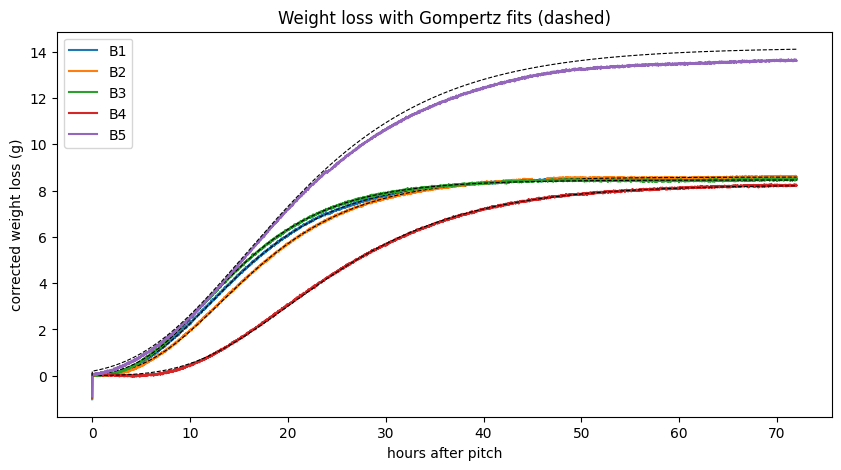

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 5))
for b, s in curves.items():
    ax.plot(s.index, s.values, label=b)
    A, mu, lam = fits[b]["A"], fits[b]["mu"], fits[b]["lam"]
    ax.plot(s.index, gompertz(s.index.values, A, mu, lam), "k--", lw=0.8)
ax.set_xlabel("hours after pitch"); ax.set_ylabel("corrected weight loss (g)")
ax.legend(); ax.set_title("Weight loss with Gompertz fits (dashed)")
plt.show()
